# Figure2 Stochastic

Reproduces panels used in the main manuscript. Generated files are written to `logs/scripts/figure2_stochastic/`.


In [1]:
import os, sys
from pathlib import Path

if Path(os.getcwd()).stem == 'scripts':
    ROOT = Path(os.getcwd()).parent
else:
    ROOT = Path(os.getcwd())

sys.path.append(str(ROOT))
os.chdir(ROOT)

In [ ]:
import re
import sys
import json
import yaml
import shlex
import random
import dotenv
import signal
import logging
import datetime
import nd2py as nd
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
from socket import gethostname
from argparse import Namespace
from argparse import ArgumentParser
from nd2py.utils import init_logger
from setproctitle import setproctitle
from src.utils import add_negation_flags, tag2ansi, log_exception
from src.core import Triplet, Individual
from src.assistant import Assistant
from src.ai_scientist import AIScientist
from src.ai_scientist_parallel import AIScientistParallel
from src.utils import wrap_ansi

import warnings
# warnings.simplefilter('error', RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="nd2py")

dotenv.load_dotenv()
_logger = logging.getLogger('src')

args = Namespace(**json.load(open('data/cache/default_args.json', 'r')))
args.save_dir = './logs/scripts'
args.exp_name = 'figure2_stochastic'
args.train_period = ['all', 'all']
args.test_period = ['all', 'all']
args.a_skill_after_2004 = 0.0

## Build Save Path
if args.exp_name is None:
    now = datetime.now()
    date = now.strftime("%Y%m%d")
    curr = now.strftime("%H%M%S")
    host = gethostname()
    exp_name = f'{date}_{args.name}_{curr}_{host}'
    exp_name = re.compile(r'[ <>:"/\\|?*\x00-\x1f]').sub('_', exp_name.strip())
    exp_name = exp_name or 'unnamed'
    exp_name = exp_name[:255] # Max filename length on most filesystems
    args.exp_name = exp_name
save_path = Path(args.save_dir) / args.exp_name
if not save_path.exists():
    save_path.mkdir(parents=True, exist_ok=True)
else:
    _logger.warning(f"Save path {save_path} already exists.")
args.save_path = str(save_path)

## Set Random State
if args.random_state is None:
    args.random_state = random.randint(0, 2**31 - 1)
## Set Command
args.command = ' '.join(map(shlex.quote, [sys.executable, *sys.argv]))

## Init Logger
init_logger(
    "src", 
    exp_name=args.exp_name, 
    log_file=save_path / "info.log", 
    info_level='debug' if args.debug else 'info',
    show_lineno_for_all_levels=args.debug,
)
nd2py_logger = logging.getLogger("nd2py")
nd2py_logger.setLevel(_logger.level)
nd2py_logger.handlers = _logger.handlers.copy()

## Save Args
args_path = save_path / "args.json"
if args_path.exists():
    i = 1
    while args_path.with_suffix(f".json.{i}").exists(): i += 1
    args_path.rename(args_path.with_suffix(f".json.{i}"))
    _logger.warning(f"args.json already exists, backup to args.json.{i}")
_logger.note(f"Args: {args}")
with open(args_path, "w") as f:
    json.dump(vars(args), f, indent=4, ensure_ascii=False)

# Start the main process
setproctitle(f"{args.exp_name}@ZihanYu")

## Load Assistant
assistant = Assistant(args)
## Load Data
# 加载变量
variables = assistant.load_variables()
# 加载数据
df_all = assistant.load_data(normalize_co2=False)
# 划分数据
if True:
    train_start, train_end = args.train_period
    test_start, test_end = args.test_period
    train_start = pd.Period(train_start, freq='M') if train_start != 'all' else df_all.index[0]
    train_end = pd.Period(train_end, freq='M') if train_end != 'all' else df_all.index[-1]
    test_start = pd.Period(test_start, freq='M') if test_start != 'all' else df_all.index[0]
    test_end = pd.Period(test_end, freq='M') if test_end != 'all' else df_all.index[-1]
    df_train = df_all.loc[train_start:train_end]
    df_test = df_all.loc[test_start:test_end]
elif False:
    df_train = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
    df_test = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
else:
    df_train = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=1999, month=12, freq='M')]
    df_test = df_all.loc[pd.Period(year=2000, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
# 准备拓扑
edge_list, num_nodes = assistant.load_topology()
# 打印日志
_logger.info(
    f"Data loaded: {len(df_all)} samples, "
    f"where {len(df_train)}({len(df_train)/len(df_all):.2%}) "
    f"from {df_train.index[0]} to {df_train.index[-1]} for training, "
    f"and {len(df_test)}({len(df_test)/len(df_all):.2%}) "
    f"from {df_test.index[0]} to {df_test.index[-1]} for testing."
)
_logger.info(
    f"Variables: " + ", ".join(f'{var_name}({len(sub_df)})' for var_name, sub_df in df_all.T.groupby(level=0)) + "."
)
## Load Seed Individuals
seed_individuals = assistant.load_seed_individuals()

## Initialize Runner
Runner = AIScientistParallel if args.parallel else AIScientist
kwargs = dict(
    args=args,
    assistant=assistant,
    variables=variables,
    binary=[
        getattr(nd, name) for name in args.binary
        # nd.Add, nd.Sub, nd.Mul, nd.Div
    ],
    unary=[
        getattr(nd, name) for name in args.unary
        # nd.Sin, nd.Cos,
        # nd.Exp, nd.LogAbs,
        # nd.Sigmoid, nd.Tanh,
        # nd.Pow2, nd.Pow3, nd.SqrtAbs,
        # nd.Aggr, nd.Readout, nd.Sour, nd.Targ,
    ],
    edge_list=edge_list,
    num_nodes=num_nodes,
    seed_individuals=seed_individuals,
)
_logger.note(f"Initializing Runner with args: {kwargs}")
est = Runner(**kwargs)
# Set Clip Bounds
est.evaluator.simulator.set_clip_bounds(df_all, clip_factor=args.clip_factor)

Save path logs/scripts/figure2_stochastic already exists.
[figure2_stochastic|src|W|Oct15 10:10:47|0:00:00.001261] (../../../../../../tmp/ipykernel_1834962/2001898168.py:84) args.json already exists, backup to args.json.3
[figure2_stochastic|src|N|Oct15 10:10:47|0:00:00.002242] Args: Namespace(name='Reduce_320_230_368', setting='only_co2', exp_name='figure2_stochastic', llm_model=None, llm_provider=None, seed_individuals=['co2_320_230_368'], load_seed_individuals=[], use_seed_individuals_only=True, num_workers=24, parallel=True, timeout=240, population_size=200, n_iter=300, programs_per_prompt=2, generate_per_prompt=8, expire_iter=1, keep_best=False, random_state=1581316702, score_func='tanh', a_rmse=0.0, a_trajrmse=0.0, a_skill_cv_sum=0.0, a_skill_cv_sum_inner=0.0, a_skill_cv_mean=0.0, a_ENSO_skill_cv=1.0, a_Total_skill_cv=10.0, a_skill_sum_inner=0.0, a_skill_sum=0.0, a_skill_mean=0.0, a_ENSO_skill=0.0, a_IOB_skill=0.0, a_SASD_skill=0.0, a_Total_skill=0.0, a_skill_after_2004=0.0, a_le

In [3]:
args.a_rmse = 0.0
args.a_trajrmse = 0.0
args.a_skill_cv_sum = 0.0
args.a_skill_cv_sum_inner = 0.0
args.a_skill_cv_mean = 0.0
args.a_ENSO_skill_cv = 1.0
args.a_ATL3_skill_cv = 1.0
args.a_SASD_skill_cv = 1.0
args.a_Total_skill_cv = 10.0
args.a_skill_sum_inner = 0.0
args.a_skill_sum = 0.0
args.a_skill_mean = 0.0
args.a_ENSO_skill = 0.0
args.a_IOB_skill = 0.0
args.a_SASD_skill = 0.0
args.a_Total_skill = 0.0
args.a_skill_after_2004 = 1.0
args.a_length = 1.0
args.a_params = 0.0
args.a_std = 0.25
args.a_skewness = 0.25
args.a_spectrum = 0.25
args.a_leadlag = 0.25
args.a_forecast = 0.0
args.a_contain_co2 = 0.0
args.max_month = 40
args.a_correlation_auc_sum = 0.0
args.a_correlation_auc_cv_sum = 0.0

args.damp = 1e-1
args.atol = 1e-6
args.btol = 1e-6
args.iter_lim = None

In [4]:
baseline_indiv = assistant.load_baseline_indiv()

def evaluate3(indiv, df_test, df_train=None, random_state=42):
    if df_train is None:
        df_train = df_test

    # Set Ground Truth Results
    _logger.info(f"Calculating ground truth result on test data...")
    est.evaluator.set_ground_truth_result(df_test)
    # Set XRO Baseline Results
    _logger.info(f"Evaluating XRO on test data as baseline...")
    baseline_dynamics = assistant.triplet_to_dynamics(baseline_indiv.triplet)
    baseline_indiv.dynamics, mse = est.evaluator.fitter.fit_parameters(baseline_dynamics, df_train, nonlinear=True)
    est.evaluator.set_baseline_result(baseline_indiv.dynamics, df_test, use_tqdm=True)
    baseline_indiv.fitness, baseline_indiv.detail = est.evaluator.get_fitness(est.evaluator.baseline_result)
    baseline_log = est.get_log_for_indiv(baseline_indiv)
    if False:
        _logger.info(tag2ansi(f"[green]Evaluate XRO on Test Data from {df_test.index[0]} to {df_test.index[-1]} (parameters are fitted on Train Data from {df_train.index[0]} to {df_train.index[-1]})[reset]"))
        _logger.info(tag2ansi("\n".join(f"[#66CCFF]{k.strip('\n')}[reset]={wrap_ansi(tag2ansi(v), 150).strip('\n')}" for k, v in baseline_log.items())))

    est.evaluator.set_fitness(indiv, df_test, df_fit=df_train, use_tqdm=True, random_state=random_state)
    log = est.get_log_for_indiv(indiv)
    _logger.info(tag2ansi(f"[green]Evaluate on Test Data from {df_test.index[0]} to {df_test.index[-1]} (parameters are fitted on Train Data from {df_train.index[0]} to {df_train.index[-1]})[reset]"))
    _logger.info(tag2ansi("\n".join(f"[#66CCFF]{k.strip('\n')}[reset]={wrap_ansi(tag2ansi(v), 150).strip('\n')}" for k, v in log.items())))

In [5]:
# df_all = assistant.load_data(normalize_co2=True)
df_all = assistant.load_data(normalize_co2=False)

triplet = assistant.program_to_triplet("""
def get_equations(t, x, h, u_co2, mode, nl_params):
    coeff = 1 + cos(t) + sin(t) + sin(0.50 * t) + sin(2 * t)
    dx_dt = x + mode['ENSO'] * h + log(u_co2) + aggr( sour(x) + tanh(0.70 * sour(h)) * (1.00 + 1.20 * targ(x) + 1.10 * readout(x)) )
    dh_dt = h + readout(x) ** 2               + aggr( sour(x) + tanh(2.00 * sour(h)) * (0.65 + 0.60 * targ(h) + 0.10 * readout(x)) )
    return coeff, dx_dt, dh_dt
""")
indiv = Individual(
    uuid=None,
    n_iter=None,
    source=None,
    parents=[],
    program=assistant.triplet_to_program(triplet),
    triplet=triplet,
    dynamics=assistant.triplet_to_dynamics(triplet),
)

args.use_nfold_cv = False
args.use_l3yo_cv = False
args.a_skill_after_2004 = 0.0
# evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])
# evaluate3(indiv, df_all.loc['1982-01':'2024-12'], df_all.loc['1982-01':'2024-12'])
# evaluate3(indiv, df_all.loc['1979-01':'1999-12'], df_all.loc['1979-01':'1999-12'])
# evaluate3(indiv, df_all.loc['1982-01':'1999-12'], df_all.loc['1982-01':'1999-12'])
# evaluate3(indiv, df_all.loc['2000-01':'2024-12'], df_all.loc['2000-01':'2024-12'])
# evaluate3(indiv, df_all.loc['2004-01':'2024-12'], df_all.loc['2004-01':'2024-12'])
# evaluate3(indiv, df_all.loc['2017-01':'2024-12'], df_all.loc['2000-01':'2016-12'])
# evaluate3(indiv, df_all.loc['2017-01':'2024-12'], df_all.loc['1979-01':'2016-12'])

# args.use_nfold_cv = True
# args.use_l3yo_cv = False
# args.lnyo_cv_N = 5
# args.lnyo_cv_N_bias = 1
# evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])
# detail_5fold_cv = indiv.detail
# detail_5fold_cv_baseline = baseline_indiv.detail

# args.use_nfold_cv = False
# args.use_l3yo_cv = True
# evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])
# detail_l3yo_cv = indiv.detail
# detail_l3yo_cv_baseline = baseline_indiv.detail

# args.use_nfold_cv = False
# args.use_l3yo_cv = False
# evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])
# detail_insample = indiv.detail
# detail_insample_baseline = baseline_indiv.detail

# args.use_nfold_cv = False
# args.use_l3yo_cv = False
# evaluate3(indiv, df_all.loc['2004-01':'2024-12'], df_all.loc['2004-01':'2024-12'])
# detail_insample_after_2004 = indiv.detail
# detail_insample_after_2004_baseline = baseline_indiv.detail

# args.use_nfold_cv = False
# args.use_l3yo_cv = False
# evaluate3(indiv, df_all.loc['2014-01':'2024-12'], df_all.loc['1979-01':'2013-12'])
# detail_outsample = indiv.detail
# detail_outsample_baseline = baseline_indiv.detail

save_dir = Path(args.save_path)
save_dir.mkdir(parents=True, exist_ok=True)

[figure2_stochastic|data_loader|I|Oct15 10:10:50|0:00:02.666353] Normalizing AOT data by min-max scaling (min=-0.018186562, max=0.2945641)
[figure2_stochastic|data_loader|I|Oct15 10:10:50|0:00:02.676751] Normalizing TSI data by min-max scaling (min=1360.7906, max=1363.2379)


In [6]:
args.use_nfold_cv = False
args.use_l3yo_cv = False
args.n_member = 10
args.generation_max_month = 240
evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'], random_state=39)
args.n_member = 10
args.generation_max_month = 120

[figure2_stochastic|src|I|Oct15 10:10:54|0:00:07.351167] Calculating ground truth result on test data...
[figure2_stochastic|src|I|Oct15 10:10:59|0:00:12.395388] Evaluating XRO on test data as baseline...


Output()

Output()

Output()

Output()

[figure2_stochastic|src|I|Oct15 10:11:31|0:00:44.356200] Evaluate on Test Data from 1979-01 to 2024-12 (parameters are fitted on Train Data from 1979-01 to 2024-12)
[figure2_stochastic|src|I|Oct15 10:11:31|0:00:44.358333] Info=None from None() at Iter None
        Fitness=4.346809
        Skills=x_ENSO=32 month; x_NPMM=17 month; x_SPMM=5 month; x_IOB=29 month; x_IOD=13 month; x_SIOD=19 month; x_TNA=10 month; x_ATL3=5 month; x_SASD=5 month; h_E
        NSO=24 month; h_NPMM=23 month; h_SPMM=20 month; h_IOB=33 month; h_IOD=24 month; h_SIOD=29 month; h_TNA=15 month; h_ATL3=6 month; h_SASD=15 month;Total
         SST=135 month;Total Z20=189 month;Total=324 month
        Skills%=x_ENSO=+68.42%;x_NPMM=-5.56%;x_SPMM=+0.00%;x_IOB=+26.09%;x_IOD=+116.67%;x_SIOD=+18.75%;x_TNA=+0.00%;x_ATL3=+25.00%;x_SASD=-28.57%;h_ENSO=+41.18%;h_NPM
        M=+21.05%;h_SPMM=+25.00%;h_IOB=+106.25%;h_IOD=+118.18%;h_SIOD=+70.59%;h_TNA=+25.00%;h_ATL3=+50.00%;h_SASD=-6.25%;SST=+25.00%;Z20=+47.66%;Total=+37.29%
        

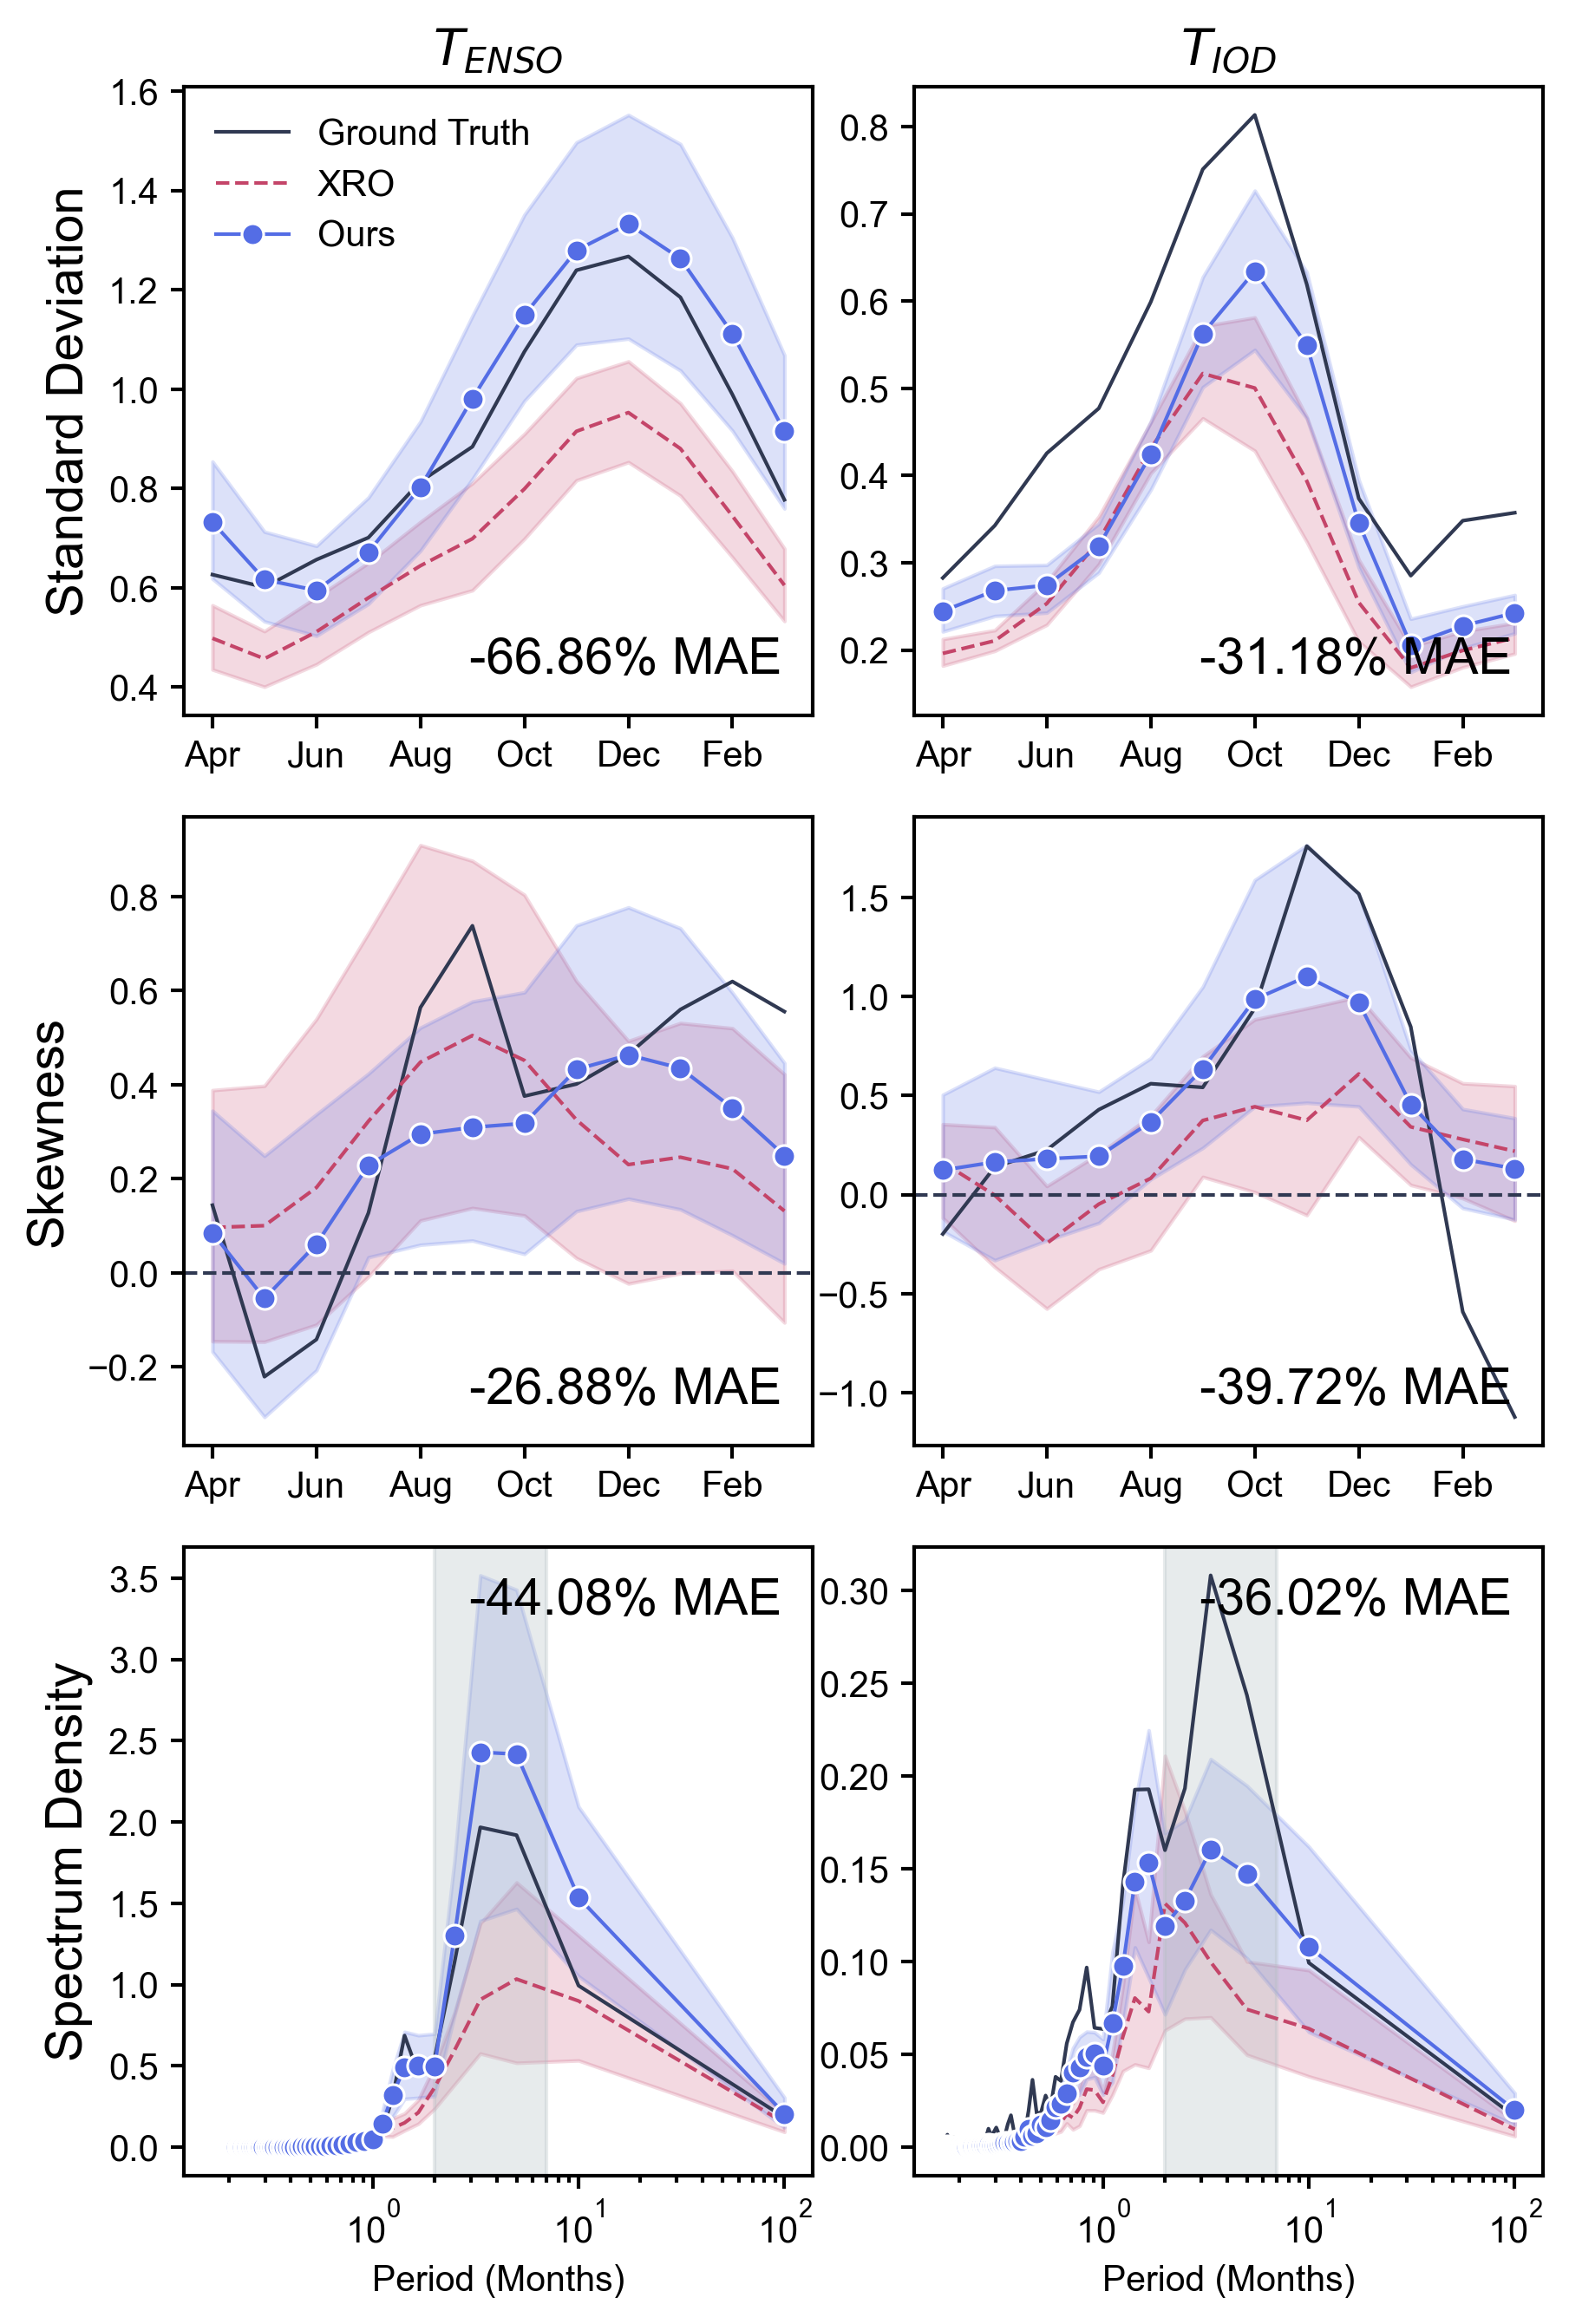

In [7]:
import seaborn as sns
from nd2py.utils.plot import get_fig, plt

df_test = df_all.loc['1979-01':'2024-12']

fi, fig, axes = get_fig(3, 2, FW=15, A_ratio=1, LM=3, TM=5, RM=0.5, BM=5, VS=2, HS=2, fontsize=14, lw=1, dpi=300)
# ax_loader = iter(axes)
axes = axes.reshape(3, 2)

var = 'x'
mode = 'ENSO'
var_map = {'x': 'T', 'h': 'h'}
ax = axes[0, 0]
if True: # Monthly Standard Deviation
    months = ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar']
    # ax = next(ax_loader)
    std0 = est.evaluator.get_monthly_std(df=df_test, var=var, mode=mode)
    sns.lineplot(
        # est.evaluator.ground_truth_result["std"].loc[months],
        std0.loc[months],
        color="#303952", ax=ax, label="Ground Truth", # marker="o", 
    )
    std2 = est.evaluator.get_monthly_std(est.evaluator.baseline_result["GENERATION"], member_average=False, var=var, mode=mode)
    sns.lineplot(
        std2
        .reset_index()
        .melt(id_vars=["member"], var_name="month", value_name="std")
        .set_index('month').loc[months].reset_index(),
        x="month", y="std", color="#c44569", ax=ax, label="XRO", linestyle='--', # marker="o",
    )
    std1 = est.evaluator.get_monthly_std(indiv.detail["GENERATION"], member_average=False, var=var, mode=mode)
    sns.lineplot(
        std1
        .reset_index()
        .melt(id_vars=["member"], var_name="month", value_name="std")
        .set_index('month').loc[months].reset_index(),
        x="month", y="std", color="#546de5", marker="o", ax=ax, label="Ours",
    )
    mae2 = np.abs(std0 - std2.mean(axis=0)).mean()
    mae1 = np.abs(std0 - std1.mean(axis=0)).mean()
    std_percent = 1 - mae1 / mae2
    ax.set_title(f'${var}_{{{mode}}}$ Monthly Standard Deviation')
    ax.set_ylabel('Standard Deviation', fontsize=0.7*fi['fontsize'])
    ax.set_xlabel('Month', fontsize=0.7*fi['fontsize'])
    ax.text(
        0.95, 0.05, f"{-std_percent:+.2%} MAE",
        transform=ax.transAxes, ha='right', va='bottom',
    )
ax.set_title(f'${var_map[var]}_{{{mode}}}$')
ax.set_ylabel('Standard Deviation', fontsize=fi['fontsize'])
ax.set_xlabel('')
ax.set_xticks(ax.get_xticks()[::2])
ax.legend(frameon=False)

var = 'x'
mode = 'ENSO'
ax = axes[1, 0]
if True: # Monthly Skewness
    # ax = next(ax_loader)
    skewness0 = est.evaluator.get_monthly_skewness(df=df_test, var=var, mode=mode)
    sns.lineplot(
        skewness0.loc[months],
        color="#303952", ax=ax, label="Ground Truth", # marker="o", 
    )
    skewness2 = est.evaluator.get_monthly_skewness(est.evaluator.baseline_result["GENERATION"], member_average=False, var=var, mode=mode)
    sns.lineplot(
        skewness2
        .reset_index()
        .melt(id_vars=["member"], var_name="month", value_name="skewness")
        .set_index('month').loc[months].reset_index(),
        x='month', y='skewness', color="#c44569", ax=ax, label="XRO", linestyle='--', # marker="o",
    )
    skewness1 = est.evaluator.get_monthly_skewness(indiv.detail["GENERATION"], member_average=False, var=var, mode=mode)
    sns.lineplot(
        skewness1
        .reset_index()
        .melt(id_vars=["member"], var_name="month", value_name="skewness")
        .set_index('month').loc[months].reset_index(),
        x='month', y='skewness', color="#546de5", marker="o", ax=ax, label="Ours"
    )
    mae2 = np.abs(skewness0 - skewness2.mean(axis=0)).mean()
    mae1 = np.abs(skewness0 - skewness1.mean(axis=0)).mean()
    skewness_percent = 1 - mae1 / mae2
    ax.legend_.remove()
    ax.axhline(0.0, linestyle='--', color='#303952')
    ax.set_title(f'${var}_{{{mode}}}$ Monthly Skewness')
    ax.set_ylabel('Skewness', fontsize=0.7*fi['fontsize'])
    ax.set_xlabel('Month', fontsize=0.7*fi['fontsize'])
    ax.text(
        0.95, 0.05, f"{-skewness_percent:+.2%} MAE",
        transform=ax.transAxes, ha='right', va='bottom',
    )
ax.set_title('')
ax.set_ylabel('Skewness', fontsize=fi['fontsize'])
ax.set_xlabel('')
ax.set_xticks(ax.get_xticks()[::2])

var = 'x'
mode = 'ENSO'
ax = axes[2, 0]
if True: # Spectrum Density
    # ax = next(ax_loader)
    spectrum0 = est.evaluator.get_spectrum_density(df=df_test, var=var, mode=mode)
    sns.lineplot(
        spectrum0
        .rename_axis('frequency')
        .rename('density')
        .reset_index()
        .pipe(lambda df: df.assign(period=(1 / df['frequency'].clip(1e-2)))),
        x='period', y='density', color='#303952', ax=ax, label='Ground Truth', # marker='o', 
    )
    spectrum2 = est.evaluator.get_spectrum_density(est.evaluator.baseline_result['GENERATION'], member_average=False, var=var, mode=mode)
    sns.lineplot(
        spectrum2
        .reset_index()
        .melt(id_vars=['member'], var_name='frequency', value_name='density')
        .pipe(lambda df: df.assign(period=(1 / df['frequency'].clip(1e-2)))),
        x='period', y='density', color='#c44569', ax=ax, label='XRO', linestyle='--', # marker='o',
    )
    spectrum1 = est.evaluator.get_spectrum_density(indiv.detail['GENERATION'], member_average=False, var=var, mode=mode)
    sns.lineplot(
        spectrum1
        .reset_index()
        .melt(id_vars=['member'], var_name='frequency', value_name='density')
        .pipe(lambda df: df.assign(period=(1 / df['frequency'].clip(1e-2)))),
        x='period', y='density', color='#546de5', marker='o', ax=ax, label='Ours'
    )
    mae2 = np.abs(spectrum0 - spectrum2.mean(axis=0)).mean()
    mae1 = np.abs(spectrum0 - spectrum1.mean(axis=0)).mean()
    spectrum_percent = 1 - mae1 / mae2
    ax.legend_.remove()
    ax.semilogx()
    ax.set_title(f'${var_map[var]}_{{{mode}}}$ Spectrum Density')
    ax.set_xlabel('Period (Months)', fontsize=0.7*fi['fontsize'])
    ax.set_ylabel('Spectrum Density', fontsize=0.7*fi['fontsize'])
    ax.axvspan(2, 7, color='#b2bec3', alpha=0.3)
    # ax.set_xlim(0.1, 100.0)
    ax.text(
        0.95, 0.95, f"{-spectrum_percent:+.2%} MAE",
        transform=ax.transAxes, ha='right', va='top',
    )
ax.set_title('')
ax.set_ylabel('Spectrum Density', fontsize=fi['fontsize'])

var = 'x'
mode = 'IOD'
ax = axes[0, 1]
if True: # Monthly Standard Deviation
    months = ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar']
    # ax = next(ax_loader)
    std0 = est.evaluator.get_monthly_std(df=df_test, var=var, mode=mode)
    sns.lineplot(
        # est.evaluator.ground_truth_result["std"].loc[months],
        std0.loc[months],
        color="#303952", ax=ax, label="Ground Truth", # marker="o", 
    )
    std2 = est.evaluator.get_monthly_std(est.evaluator.baseline_result["GENERATION"], member_average=False, var=var, mode=mode)
    sns.lineplot(
        std2
        .reset_index()
        .melt(id_vars=["member"], var_name="month", value_name="std")
        .set_index('month').loc[months].reset_index(),
        x="month", y="std", color="#c44569", ax=ax, label="XRO", linestyle='--', # marker="o",
    )
    std1 = est.evaluator.get_monthly_std(indiv.detail["GENERATION"], member_average=False, var=var, mode=mode)
    sns.lineplot(
        std1
        .reset_index()
        .melt(id_vars=["member"], var_name="month", value_name="std")
        .set_index('month').loc[months].reset_index(),
        x="month", y="std", color="#546de5", marker="o", ax=ax, label="Ours",
    )
    mae2 = np.abs(std0 - std2.mean(axis=0)).mean()
    mae1 = np.abs(std0 - std1.mean(axis=0)).mean()
    std_percent = 1 - mae1 / mae2
    ax.set_title(f'${var_map[var]}_{{{mode}}}$ Monthly Standard Deviation')
    ax.set_ylabel('Standard Deviation', fontsize=0.7*fi['fontsize'])
    ax.set_xlabel('Month', fontsize=0.7*fi['fontsize'])
    ax.text(
        0.95, 0.05, f"{-std_percent:+.2%} MAE",
        transform=ax.transAxes, ha='right', va='bottom',
    )
ax.set_title(f'${var_map[var]}_{{{mode}}}$')
ax.set_ylabel('')
ax.set_xlabel('')
ax.set_xticks(ax.get_xticks()[::2])
ax.legend_.remove()

var = 'x'
mode = 'IOD'
ax = axes[1, 1]
if True: # Monthly Skewness
    # ax = next(ax_loader)
    skewness0 = est.evaluator.get_monthly_skewness(df=df_test, var=var, mode=mode)
    sns.lineplot(
        skewness0.loc[months],
        color="#303952", ax=ax, label="Ground Truth", # marker="o", 
    )
    skewness2 = est.evaluator.get_monthly_skewness(est.evaluator.baseline_result["GENERATION"], member_average=False, var=var, mode=mode)
    sns.lineplot(
        skewness2
        .reset_index()
        .melt(id_vars=["member"], var_name="month", value_name="skewness")
        .set_index('month').loc[months].reset_index(),
        x='month', y='skewness', color="#c44569", ax=ax, label="XRO", linestyle='--', # marker="o",
    )
    skewness1 = est.evaluator.get_monthly_skewness(indiv.detail["GENERATION"], member_average=False, var=var, mode=mode)
    sns.lineplot(
        skewness1
        .reset_index()
        .melt(id_vars=["member"], var_name="month", value_name="skewness")
        .set_index('month').loc[months].reset_index(),
        x='month', y='skewness', color="#546de5", marker="o", ax=ax, label="Ours"
    )
    mae2 = np.abs(skewness0 - skewness2.mean(axis=0)).mean()
    mae1 = np.abs(skewness0 - skewness1.mean(axis=0)).mean()
    skewness_percent = 1 - mae1 / mae2
    ax.legend_.remove()
    ax.axhline(0.0, linestyle='--', color='#303952')
    ax.set_title(f'${var_map[var]}_{{{mode}}}$ Monthly Skewness')
    ax.set_ylabel('Skewness', fontsize=0.7*fi['fontsize'])
    ax.set_xlabel('Month', fontsize=0.7*fi['fontsize'])
    ax.text(
        0.95, 0.05, f"{-skewness_percent:+.2%} MAE",
        transform=ax.transAxes, ha='right', va='bottom',
    )
ax.set_title('')
ax.set_ylabel('')
ax.set_xlabel('')
ax.set_xticks(ax.get_xticks()[::2])

var = 'x'
mode = 'IOD'
ax = axes[2, 1]
if True: # Spectrum Density
    # ax = next(ax_loader)
    spectrum0 = est.evaluator.get_spectrum_density(df=df_test, var=var, mode=mode)
    sns.lineplot(
        spectrum0
        .rename_axis('frequency')
        .rename('density')
        .reset_index()
        .pipe(lambda df: df.assign(period=(1 / df['frequency'].clip(1e-2)))),
        x='period', y='density', color='#303952', ax=ax, label='Ground Truth', # marker='o', 
    )
    spectrum2 = est.evaluator.get_spectrum_density(est.evaluator.baseline_result['GENERATION'], member_average=False, var=var, mode=mode)
    sns.lineplot(
        spectrum2
        .reset_index()
        .melt(id_vars=['member'], var_name='frequency', value_name='density')
        .pipe(lambda df: df.assign(period=(1 / df['frequency'].clip(1e-2)))),
        x='period', y='density', color='#c44569', ax=ax, label='XRO', linestyle='--', # marker='o',
    )
    spectrum1 = est.evaluator.get_spectrum_density(indiv.detail['GENERATION'], member_average=False, var=var, mode=mode)
    sns.lineplot(
        spectrum1
        .reset_index()
        .melt(id_vars=['member'], var_name='frequency', value_name='density')
        .pipe(lambda df: df.assign(period=(1 / df['frequency'].clip(1e-2)))),
        x='period', y='density', color='#546de5', marker='o', ax=ax, label='Ours'
    )
    mae2 = np.abs(spectrum0 - spectrum2.mean(axis=0)).mean()
    mae1 = np.abs(spectrum0 - spectrum1.mean(axis=0)).mean()
    spectrum_percent = 1 - mae1 / mae2
    ax.legend_.remove()
    ax.semilogx()
    ax.set_title(f'${var_map[var]}_{{{mode}}}$ Spectrum Density')
    ax.set_xlabel('Period (Months)', fontsize=0.7*fi['fontsize'])
    ax.set_ylabel('Spectrum Density', fontsize=0.7*fi['fontsize'])
    ax.axvspan(2, 7, color='#b2bec3', alpha=0.3)
    # ax.set_xlim(0.1, 100.0)
    ax.text(
        0.95, 0.95, f"{-spectrum_percent:+.2%} MAE",
        transform=ax.transAxes, ha='right', va='top',
    )
ax.set_title('')
ax.set_ylabel('')

fig.savefig(save_dir / 'Fig2g-h.svg', transparent=True, dpi=300)
fig.savefig(save_dir / 'Fig2g-h.png', transparent=True, dpi=300)
fig.savefig(save_dir / 'Fig2g-h.pdf', transparent=True, dpi=300)